# Detección de anomalías para identificación de fraude en comercio electrónico

Se aplican técnicas de detección de anomalías sobre un conjunto de datos de transacciones de comercio electrónico para identificar posibles fraudes. El problema se aborda desde tres perspectivas complementarias:

1. **Anomalías puntuales**, donde una transacción individual resulta atípica respecto al comportamiento global.
2. **Anomalías contextuales**, donde una transacción puede ser anómala al considerar varias variables simultáneamente.
3. **Anomalías colectivas**, donde el comportamiento anómalo aparece como una desviación agregada en una secuencia temporal de transacciones.

La variable `Is Fraudulent` se utiliza únicamente para evaluar los resultados obtenidos, no para entrenar los modelos no supervisados.


## 0. Carga de librerías y funciones comunes


In [1]:
import os
import sys
import subprocess
import warnings
from pathlib import Path

warnings.filterwarnings('ignore')

# Dependencia utilizada para detección de cambios temporales mediante PELT.
try:
    import ruptures as rpt
except ImportError:
    subprocess.check_call([sys.executable, '-m', 'pip', 'install', 'ruptures'])
    import ruptures as rpt

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from IPython.display import display

from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.impute import SimpleImputer
from sklearn.ensemble import IsolationForest
from sklearn.neighbors import LocalOutlierFactor
from sklearn.svm import OneClassSVM
from sklearn.metrics import confusion_matrix, accuracy_score, precision_recall_fscore_support

RANDOM_STATE = 42
np.random.seed(RANDOM_STATE)

pd.set_option('display.max_columns', 100)
pd.set_option('display.width', 160)
plt.rcParams['figure.figsize'] = (9, 5)
plt.rcParams['axes.grid'] = True

print('Librerías cargadas correctamente.')


Librerías cargadas correctamente.


In [2]:
def buscar_archivo(candidatos):
    # Devuelve la primera ruta existente entre varias alternativas.
    for candidato in candidatos:
        ruta = Path(candidato)
        if ruta.exists():
            return ruta
    raise FileNotFoundError(f'No se ha encontrado ninguno de estos archivos: {candidatos}')


def metricas_binarias(y_true, y_pred, nombre_modelo):
    # Calcula métricas centradas en la clase fraudulenta/anómala.
    y_true = np.asarray(y_true).astype(int)
    y_pred = np.asarray(y_pred).astype(int)
    tn, fp, fn, tp = confusion_matrix(y_true, y_pred, labels=[0, 1]).ravel()
    precision, recall, f1, _ = precision_recall_fscore_support(
        y_true, y_pred, labels=[1], average='binary', zero_division=0
    )
    return {
        'modelo': nombre_modelo,
        'TN': tn,
        'FP': fp,
        'FN': fn,
        'TP': tp,
        'accuracy': accuracy_score(y_true, y_pred),
        'precision_fraude': precision,
        'recall_fraude': recall,
        'f1_fraude': f1,
        'tasa_predicha_anomalia': y_pred.mean()
    }


def mostrar_matriz_confusion(y_true, y_pred, titulo):
    cm = confusion_matrix(y_true, y_pred, labels=[0, 1])
    fig, ax = plt.subplots(figsize=(4.5, 4))
    im = ax.imshow(cm)
    ax.set_title(titulo)
    ax.set_xlabel('Predicción')
    ax.set_ylabel('Valor real')
    ax.set_xticks([0, 1])
    ax.set_yticks([0, 1])
    ax.set_xticklabels(['No fraude', 'Fraude'])
    ax.set_yticklabels(['No fraude', 'Fraude'])
    for i in range(2):
        for j in range(2):
            ax.text(j, i, cm[i, j], ha='center', va='center')
    fig.colorbar(im, ax=ax, fraction=0.046, pad=0.04)
    plt.tight_layout()
    plt.show()


def formatear_metricas(df_metricas):
    columnas_pct = ['accuracy', 'precision_fraude', 'recall_fraude', 'f1_fraude', 'tasa_predicha_anomalia']
    df = df_metricas.copy()
    for col in columnas_pct:
        df[col] = (100 * df[col]).round(2)
    return df


## 1. Carga de datos

Se cargan los dos ficheros CSV reales de transacciones. El primer fichero se utiliza como conjunto de referencia/entrenamiento y el segundo como conjunto de evaluación. Dado el tamaño del primer fichero, se toma una muestra reproducible del 10 % para mantener el análisis ejecutable y trazable. El segundo fichero se utiliza completo, ya que su tamaño permite evaluar los métodos sin coste computacional excesivo.


In [3]:
train_path = buscar_archivo([
    'data/Fraudulent_E-Commerce_Transaction_Data.csv',
    'Fraudulent_E-Commerce_Transaction_Data.csv'
])

test_path = buscar_archivo([
    'data/Fraudulent_E-Commerce_Transaction_Data_2.csv',
    'Fraudulent_E-Commerce_Transaction_Data_2.csv'
])

columnas = [
    'Transaction ID', 'Customer ID', 'Transaction Amount', 'Transaction Date',
    'Payment Method', 'Product Category', 'Quantity', 'Customer Age',
    'Customer Location', 'Device Used', 'IP Address', 'Shipping Address',
    'Billing Address', 'Is Fraudulent', 'Account Age Days', 'Transaction Hour'
]

tipos = {
    'Transaction Amount': 'float32',
    'Quantity': 'int16',
    'Customer Age': 'int16',
    'Is Fraudulent': 'int8',
    'Account Age Days': 'int16',
    'Transaction Hour': 'int8'
}

df_train = pd.read_csv(train_path, usecols=columnas, dtype=tipos, on_bad_lines='skip')
df_test = pd.read_csv(test_path, usecols=columnas, dtype=tipos, on_bad_lines='skip')

# Muestreo reproducible sobre el fichero grande de entrenamiento.
df_train = df_train.sample(frac=0.10, random_state=RANDOM_STATE).reset_index(drop=True)
df_test = df_test.reset_index(drop=True)

print(f'Archivo de entrenamiento: {train_path}')
print(f'Archivo de evaluación: {test_path}')
print(f'Dimensiones del conjunto de entrenamiento: {df_train.shape}')
print(f'Dimensiones del conjunto de evaluación: {df_test.shape}')

display(df_train.head())


Archivo de entrenamiento: Fraudulent_E-Commerce_Transaction_Data.csv
Archivo de evaluación: Fraudulent_E-Commerce_Transaction_Data_2(1).csv
Dimensiones del conjunto de entrenamiento: (147295, 16)
Dimensiones del conjunto de evaluación: (23634, 16)


,Transaction ID,Customer ID,Transaction Amount,Transaction Date,Payment Method,Product Category,Quantity,Customer Age,Customer Location,Device Used,IP Address,Shipping Address,Billing Address,Is Fraudulent,Account Age Days,Transaction Hour
0,69c99073-bf9a-4f39-87d6-0bac726fe43b,37fc6628-9d40-477c-b576-4e739af7eb51,84.910004,2024-03-30 19:07:37,bank transfer,electronics,1,31,South Richard,tablet,78.16.79.0,297 Anthony Creek Suite 388\nNorth Michaelfurt...,297 Anthony Creek Suite 388\nNorth Michaelfurt...,0,34,19
1,7eae0592-d64b-45f0-aa01-b4d224328a0b,14f1b38e-72f1-4a82-aa5a-d422aa990279,30.990000,2024-02-23 02:10:27,credit card,electronics,3,47,Amberside,mobile,102.33.181.96,USNV Diaz\nFPO AA 86306,USNV Diaz\nFPO AA 86306,0,95,2
2,16ad4695-16d5-4b6e-b65d-0308473d82c1,a7f6f1a6-220d-44eb-b8b8-e27a655e5cdc,310.320007,2024-01-05 19:14:48,debit card,clothing,4,50,South Brianburgh,mobile,139.222.215.225,"588 Darrell Neck\nTannerville, OR 16918","588 Darrell Neck\nTannerville, OR 16918",0,304,19
3,271e4574-c2cc-422e-96cd-2ac4cb25d8e0,801e4f9f-ed11-4992-9ff1-d2ab329e72b7,40.500000,2024-02-18 15:44:20,bank transfer,home & garden,1,38,Christianfort,tablet,166.120.49.97,"98931 Teresa Glen\nEast Donna, AZ 79166","98931 Teresa Glen\nEast Donna, AZ 79166",0,14,15
4,e409f671-5c17-43f0-a7ed-06d2a648c5eb,0f97f0b6-0575-4e51-8b5d-571e2ec27cd3,537.909973,2024-02-25 13:48:44,debit card,home & garden,2,31,Sarafort,tablet,144.152.197.120,"11610 Miller Ford Suite 999\nTaraborough, MN 2...","11610 Miller Ford Suite 999\nTaraborough, MN 2...",0,274,13


## 2. Análisis exploratorio de datos

Se estudian la estructura del conjunto, la distribución de la variable objetivo, las variables numéricas y categóricas y la tasa de fraude en distintos contextos operativos.

In [4]:
print('Información general del conjunto de entrenamiento')
print(df_train.info())

resumen_basico = pd.DataFrame({
    'tipo': df_train.dtypes.astype(str),
    'nulos': df_train.isna().sum(),
    'porcentaje_nulos': (100 * df_train.isna().mean()).round(3),
    'valores_unicos': df_train.nunique(dropna=True)
})

display(resumen_basico)

duplicados_transaccion = df_train.duplicated(subset=['Transaction ID']).sum()
print(f'Transacciones duplicadas por Transaction ID: {duplicados_transaccion}')


Información general del conjunto de entrenamiento
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 147295 entries, 0 to 147294
Data columns (total 16 columns):
 #   Column              Non-Null Count   Dtype  
---  ------              --------------   -----  
 0   Transaction ID      147295 non-null  object 
 1   Customer ID         147295 non-null  object 
 2   Transaction Amount  147295 non-null  float32
 3   Transaction Date    147295 non-null  object 
 4   Payment Method      147295 non-null  object 
 5   Product Category    147295 non-null  object 
 6   Quantity            147295 non-null  int16  
 7   Customer Age        147295 non-null  int16  
 8   Customer Location   147295 non-null  object 
 9   Device Used         147295 non-null  object 
 10  IP Address          147295 non-null  object 
 11  Shipping Address    147295 non-null  object 
 12  Billing Address     147295 non-null  object 
 13  Is Fraudulent       147295 non-null  int8   
 14  Account Age Days    147295 non-nul

,tipo,nulos,porcentaje_nulos,valores_unicos
Transaction ID,object,0,0.0,147295
Customer ID,object,0,0.0,147295
Transaction Amount,float32,0,0.0,52811
Transaction Date,object,0,0.0,145908
Payment Method,object,0,0.0,4
Product Category,object,0,0.0,5
Quantity,int16,0,0.0,5
Customer Age,int16,0,0.0,83
Customer Location,object,0,0.0,46559
Device Used,object,0,0.0,3


Transacciones duplicadas por Transaction ID: 0


,frecuencia,porcentaje
Is Fraudulent,,
No fraudulenta,139909,94.99
Fraudulenta,7386,5.01


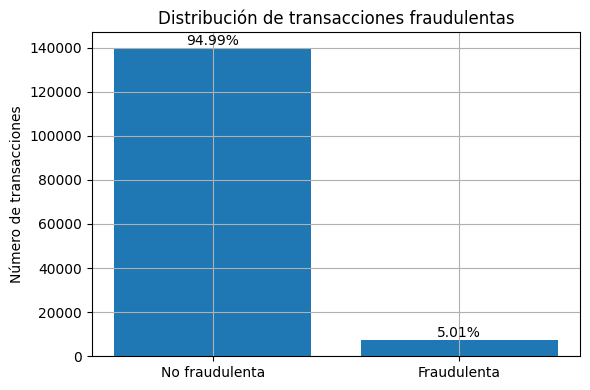

In [5]:
# Distribución de la variable objetivo
fraud_dist = df_train['Is Fraudulent'].value_counts().sort_index().rename(index={0: 'No fraudulenta', 1: 'Fraudulenta'})
fraud_pct = (100 * fraud_dist / fraud_dist.sum()).round(2)
fraud_table = pd.DataFrame({'frecuencia': fraud_dist, 'porcentaje': fraud_pct})
display(fraud_table)

fig, ax = plt.subplots(figsize=(6, 4))
ax.bar(fraud_table.index.astype(str), fraud_table['frecuencia'])
ax.set_title('Distribución de transacciones fraudulentas')
ax.set_ylabel('Número de transacciones')
for i, v in enumerate(fraud_table['frecuencia']):
    ax.text(i, v, f'{fraud_table.iloc[i]["porcentaje"]}%', ha='center', va='bottom')
plt.tight_layout()
plt.show()


,count,mean,std,min,25%,50%,75%,max,asimetria,curtosis
Transaction Amount,147295.0,226.566,273.057,10.0,68.58,151.9,295.595,9221.6,6.135,82.566
Quantity,147295.0,2.998,1.415,1.0,2.00,3.0,4.000,5.0,0.001,-1.301
Customer Age,147295.0,34.526,10.007,-6.0,28.00,35.0,41.000,86.0,0.004,-0.012
Account Age Days,147295.0,179.864,106.944,1.0,86.00,180.0,273.000,365.0,0.016,-1.222
Transaction Hour,147295.0,11.282,6.987,0.0,5.00,11.0,17.000,23.0,0.034,-1.230


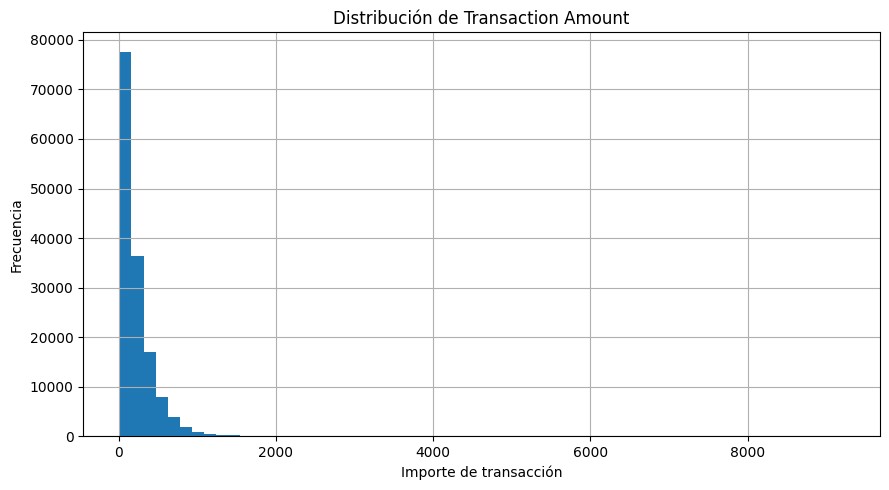

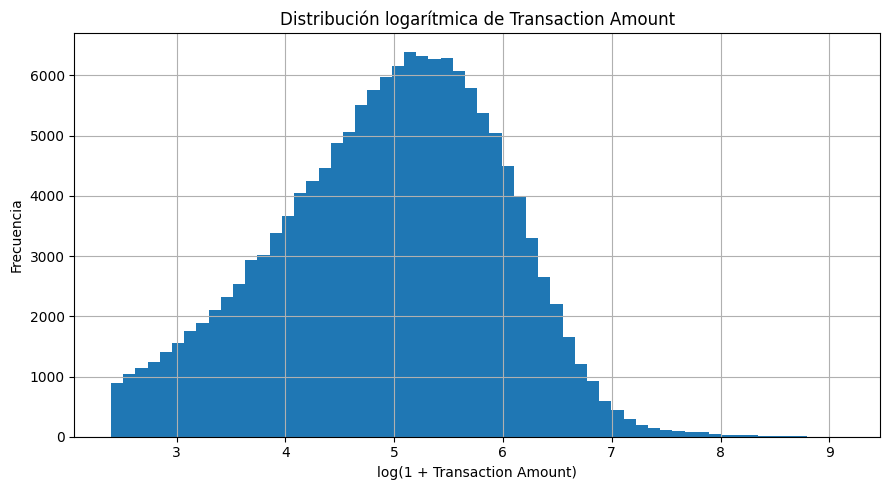

In [6]:
# Resumen de variables numéricas
variables_numericas = ['Transaction Amount', 'Quantity', 'Customer Age', 'Account Age Days', 'Transaction Hour']
resumen_numerico = df_train[variables_numericas].describe().T
resumen_numerico['asimetria'] = df_train[variables_numericas].skew(numeric_only=True)
resumen_numerico['curtosis'] = df_train[variables_numericas].kurtosis(numeric_only=True)
display(resumen_numerico.round(3))

fig, ax = plt.subplots(figsize=(9, 5))
ax.hist(df_train['Transaction Amount'], bins=60)
ax.set_title('Distribución de Transaction Amount')
ax.set_xlabel('Importe de transacción')
ax.set_ylabel('Frecuencia')
plt.tight_layout()
plt.show()

fig, ax = plt.subplots(figsize=(9, 5))
ax.hist(np.log1p(df_train['Transaction Amount']), bins=60)
ax.set_title('Distribución logarítmica de Transaction Amount')
ax.set_xlabel('log(1 + Transaction Amount)')
ax.set_ylabel('Frecuencia')
plt.tight_layout()
plt.show()



Distribución de Payment Method


,frecuencia,porcentaje
Payment Method,,
PayPal,36956,25.09
bank transfer,36858,25.02
debit card,36851,25.02
credit card,36630,24.87



Distribución de Product Category


,frecuencia,porcentaje
Product Category,,
health & beauty,29633,20.12
electronics,29625,20.11
toys & games,29498,20.03
clothing,29314,19.90
home & garden,29225,19.84



Distribución de Device Used


,frecuencia,porcentaje
Device Used,,
tablet,49261,33.44
mobile,49154,33.37
desktop,48880,33.19


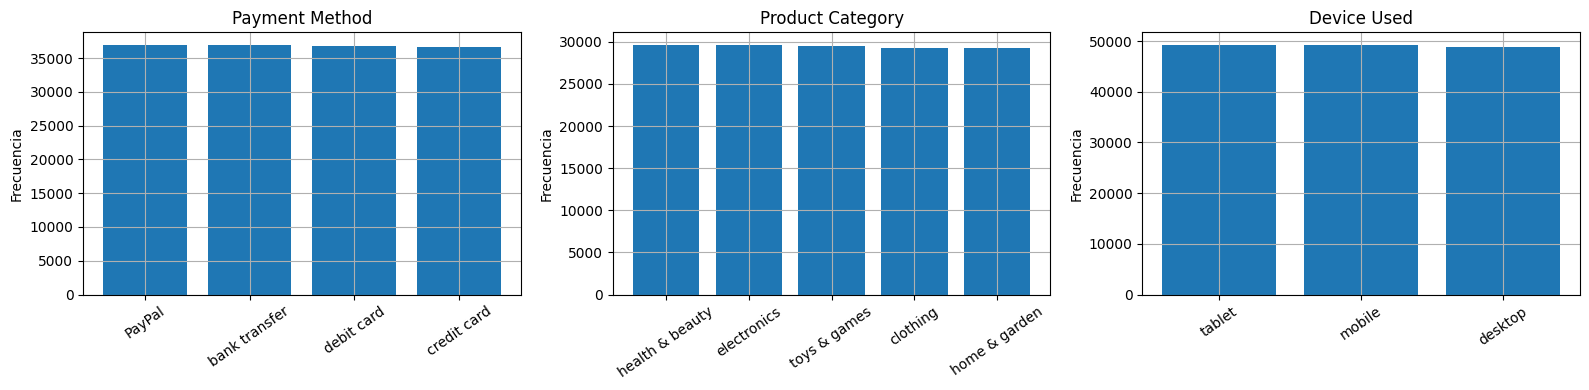

In [7]:
# Distribución de variables categóricas relevantes
variables_categoricas = ['Payment Method', 'Product Category', 'Device Used']
for col in variables_categoricas:
    tabla = df_train[col].value_counts().to_frame('frecuencia')
    tabla['porcentaje'] = (100 * tabla['frecuencia'] / tabla['frecuencia'].sum()).round(2)
    print(f'\nDistribución de {col}')
    display(tabla)

fig, axes = plt.subplots(1, 3, figsize=(16, 4))
for ax, col in zip(axes, variables_categoricas):
    conteos = df_train[col].value_counts()
    ax.bar(conteos.index.astype(str), conteos.values)
    ax.set_title(col)
    ax.tick_params(axis='x', rotation=35)
    ax.set_ylabel('Frecuencia')
plt.tight_layout()
plt.show()


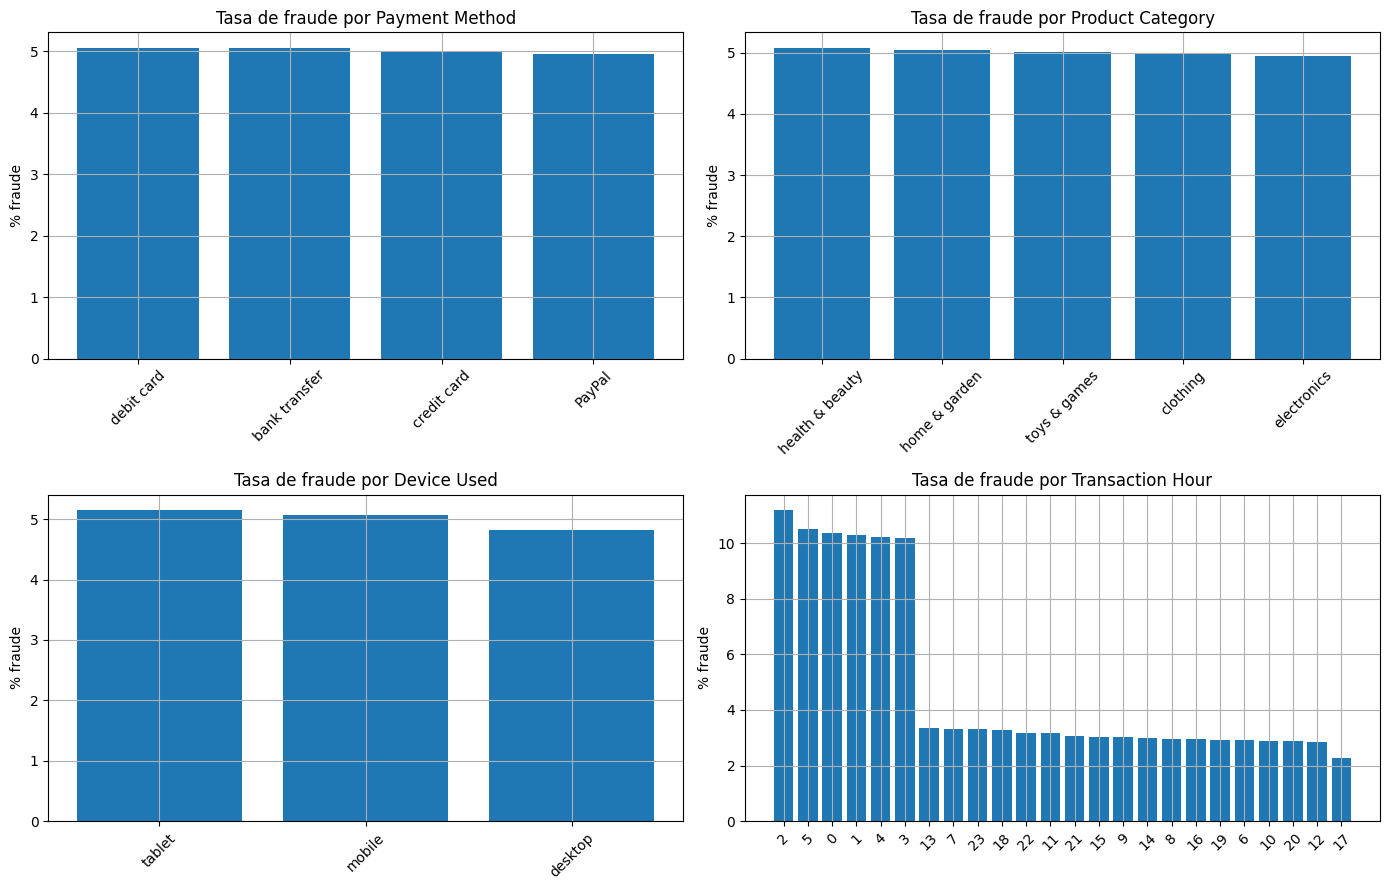

,No fraudulenta,Fraudulenta
Misma dirección,94.95,5.05
Dirección diferente,95.31,4.69


In [8]:
# Tasa de fraude por contexto operativo
fig, axes = plt.subplots(2, 2, figsize=(14, 9))
contextos = ['Payment Method', 'Product Category', 'Device Used', 'Transaction Hour']
for ax, col in zip(axes.ravel(), contextos):
    tasa = df_train.groupby(col)['Is Fraudulent'].mean().sort_values(ascending=False)
    ax.bar(tasa.index.astype(str), 100 * tasa.values)
    ax.set_title(f'Tasa de fraude por {col}')
    ax.set_ylabel('% fraude')
    ax.tick_params(axis='x', rotation=45)
plt.tight_layout()
plt.show()

# Diferencia entre dirección de envío y facturación
address_mismatch_train = (df_train['Shipping Address'] != df_train['Billing Address']).astype(int)
address_table = pd.crosstab(address_mismatch_train, df_train['Is Fraudulent'], normalize='index')
address_table.index = ['Misma dirección', 'Dirección diferente']
address_table.columns = ['No fraudulenta', 'Fraudulenta']
display((100 * address_table).round(2))


### Análisis de resultados

El conjunto de datos contiene transacciones de comercio electrónico con información financiera, temporal, categórica, técnica y de cliente. Los principales resultados del análisis exploratorio son los siguientes:

- La variable objetivo está desbalanceada: la clase fraudulenta representa una proporción reducida respecto a la clase legítima. Esto implica que la exactitud global no es suficiente para valorar los modelos; deben analizarse especialmente la precisión, el recall y el F1 de la clase fraudulenta.
- `Transaction Amount` es una variable continua relevante para la detección de anomalías puntuales. Su distribución presenta dispersión y valores extremos, por lo que resulta razonable aplicar métodos estadísticos univariantes como Z-score, IQR o MAD.
- Las variables `Payment Method`, `Product Category` y `Device Used` tienen baja cardinalidad y pueden codificarse mediante one-hot encoding para los modelos multivariantes.
- `Transaction ID`, `Customer ID`, `IP Address`, `Shipping Address` y `Billing Address` son variables identificativas o de cardinalidad muy alta. No se usan directamente como variables categóricas en los modelos, pero sí se extrae una señal útil a partir de la comparación entre dirección de envío y dirección de facturación.
- La hora de la transacción y la fecha permiten construir variables temporales como día de la semana, operación nocturna o fin de semana, útiles para detección contextual y colectiva.


## 3. Preprocesamiento y tratamiento de variables

Se preparan los datos para los modelos no supervisados: ingeniería de variables temporales y de comportamiento, transformación de variables numéricas y codificación de las categóricas.

In [9]:
def ingenieria_variables(df):
    df = df.copy()
    df['Transaction Date'] = pd.to_datetime(df['Transaction Date'], errors='coerce')
    df['date'] = df['Transaction Date'].dt.date
    df['dayofweek'] = df['Transaction Date'].dt.dayofweek.astype('float32')
    df['is_weekend'] = df['dayofweek'].isin([5, 6]).astype('int8')
    df['is_night'] = df['Transaction Hour'].isin([0, 1, 2, 3, 4, 5]).astype('int8')
    df['address_mismatch'] = (df['Shipping Address'] != df['Billing Address']).astype('int8')
    df['amount_per_item'] = df['Transaction Amount'] / df['Quantity'].replace(0, np.nan)
    df['log_amount'] = np.log1p(df['Transaction Amount'].clip(lower=0))
    return df


def agregar_ratios_contextuales(train, test):
    train = train.copy()
    test = test.copy()
    columnas_contexto = ['Product Category', 'Payment Method', 'Device Used', 'Transaction Hour']
    mediana_global = train['Transaction Amount'].median()

    for col in columnas_contexto:
        mediana_contexto = train.groupby(col)['Transaction Amount'].median().rename(f'median_amount_by_{col}')
        train = train.merge(mediana_contexto, left_on=col, right_index=True, how='left')
        test = test.merge(mediana_contexto, left_on=col, right_index=True, how='left')

        train[f'median_amount_by_{col}'] = train[f'median_amount_by_{col}'].fillna(mediana_global)
        test[f'median_amount_by_{col}'] = test[f'median_amount_by_{col}'].fillna(mediana_global)

        train[f'amount_ratio_{col}'] = train['Transaction Amount'] / (train[f'median_amount_by_{col}'] + 1e-6)
        test[f'amount_ratio_{col}'] = test['Transaction Amount'] / (test[f'median_amount_by_{col}'] + 1e-6)

        train = train.drop(columns=[f'median_amount_by_{col}'])
        test = test.drop(columns=[f'median_amount_by_{col}'])

    return train, test


df_train_proc = ingenieria_variables(df_train)
df_test_proc = ingenieria_variables(df_test)
df_train_proc, df_test_proc = agregar_ratios_contextuales(df_train_proc, df_test_proc)

variables_numericas_modelo = [
    'Transaction Amount', 'log_amount', 'Quantity', 'Customer Age', 'Account Age Days',
    'Transaction Hour', 'dayofweek', 'is_weekend', 'is_night', 'address_mismatch',
    'amount_per_item', 'amount_ratio_Product Category', 'amount_ratio_Payment Method',
    'amount_ratio_Device Used', 'amount_ratio_Transaction Hour'
]
variables_categoricas_modelo = ['Payment Method', 'Product Category', 'Device Used']
variables_modelo = variables_numericas_modelo + variables_categoricas_modelo

print('Variables numéricas del modelo:')
print(variables_numericas_modelo)
print('\nVariables categóricas del modelo:')
print(variables_categoricas_modelo)

display(df_train_proc[variables_modelo + ['Is Fraudulent']].head())


Variables numéricas del modelo:
['Transaction Amount', 'log_amount', 'Quantity', 'Customer Age', 'Account Age Days', 'Transaction Hour', 'dayofweek', 'is_weekend', 'is_night', 'address_mismatch', 'amount_per_item', 'amount_ratio_Product Category', 'amount_ratio_Payment Method', 'amount_ratio_Device Used', 'amount_ratio_Transaction Hour']

Variables categóricas del modelo:
['Payment Method', 'Product Category', 'Device Used']


,Transaction Amount,log_amount,Quantity,Customer Age,Account Age Days,Transaction Hour,dayofweek,is_weekend,is_night,address_mismatch,amount_per_item,amount_ratio_Product Category,amount_ratio_Payment Method,amount_ratio_Device Used,amount_ratio_Transaction Hour,Payment Method,Product Category,Device Used,Is Fraudulent
0,84.910004,4.453300,1,31,34,19,5.0,1,0,0,84.910004,0.554207,0.561518,0.556021,0.566444,bank transfer,electronics,tablet,0
1,30.990000,3.465423,3,47,95,2,4.0,0,1,0,10.330000,0.202271,0.202715,0.204642,0.200466,credit card,electronics,mobile,0
2,310.320007,5.740821,4,50,304,19,4.0,0,0,0,77.580002,2.071769,2.032886,2.049196,2.070180,debit card,clothing,mobile,0
3,40.500000,3.725693,1,38,14,15,6.0,1,0,0,40.500000,0.263826,0.267831,0.265209,0.271202,bank transfer,home & garden,tablet,0
4,537.909973,6.289548,2,31,274,13,6.0,1,0,0,268.954987,3.504071,3.523813,3.522428,3.657634,debit card,home & garden,tablet,0


In [10]:
# Pipeline de transformación para modelos multivariantes
try:
    encoder = OneHotEncoder(handle_unknown='ignore', sparse_output=False)
except TypeError:
    encoder = OneHotEncoder(handle_unknown='ignore', sparse=False)

preprocesador = ColumnTransformer(
    transformers=[
        ('num', Pipeline(steps=[
            ('imputer', SimpleImputer(strategy='median')),
            ('scaler', StandardScaler())
        ]), variables_numericas_modelo),
        ('cat', Pipeline(steps=[
            ('imputer', SimpleImputer(strategy='most_frequent')),
            ('onehot', encoder)
        ]), variables_categoricas_modelo)
    ],
    remainder='drop'
)

# El preprocesador se ajusta en entrenamiento. No se usa la variable objetivo.
preprocesador.fit(df_train_proc[variables_modelo].sample(n=min(50000, len(df_train_proc)), random_state=RANDOM_STATE))

X_test_contextual = preprocesador.transform(df_test_proc[variables_modelo])
y_test = df_test_proc['Is Fraudulent'].astype(int).values

print(f'Matriz de evaluación transformada: {X_test_contextual.shape}')


Matriz de evaluación transformada: (23634, 27)


### Análisis de resultados

El preprocesamiento se ha realizado con tres objetivos: eliminar ruido operativo, transformar variables para que puedan ser usadas por modelos no supervisados y generar información contextual adicional.

- Se transforma `Transaction Date` a formato temporal y se derivan variables como `dayofweek`, `is_weekend` e `is_night`.
- Se crea `address_mismatch`, que identifica si la dirección de envío y facturación son distintas. Esta variable resume información útil sin introducir direcciones completas de cardinalidad alta.
- Se crea `amount_per_item`, que normaliza el importe por número de unidades compradas.
- Se usa `log_amount` para reducir la influencia de valores extremos del importe.
- Se crean ratios contextuales del importe frente a la mediana por categoría, método de pago, dispositivo y hora. Estas variables permiten detectar transacciones que no solo son grandes en términos absolutos, sino también inusuales dentro de su contexto.
- Las variables numéricas se imputan por mediana y se estandarizan. Las variables categóricas de baja cardinalidad se imputan por moda y se codifican mediante one-hot encoding.


## 4. Detección de anomalías puntuales

Se evalúa si el importe de la transacción (`Transaction Amount`) por sí solo permite detectar fraude, mediante métodos estadísticos univariantes.

In [11]:
x_train = df_train_proc['Transaction Amount'].astype(float)
x_test = df_test_proc['Transaction Amount'].astype(float)

predicciones_puntuales = {}

# Z-score clásico
media = x_train.mean()
desv = x_train.std(ddof=0)
z_scores = (x_test - media) / (desv + 1e-9)
predicciones_puntuales['Z-score |z| > 3'] = (np.abs(z_scores) > 3).astype(int).values

# IQR
q1, q3 = x_train.quantile([0.25, 0.75])
iqr = q3 - q1
limite_inferior_iqr = q1 - 1.5 * iqr
limite_superior_iqr = q3 + 1.5 * iqr
predicciones_puntuales['IQR 1.5'] = ((x_test < limite_inferior_iqr) | (x_test > limite_superior_iqr)).astype(int).values

# MAD / modified Z-score
mediana = x_train.median()
mad = np.median(np.abs(x_train - mediana))
modified_z = 0.6745 * (x_test - mediana) / (mad + 1e-9)
predicciones_puntuales['MAD |z_mod| > 3.5'] = (np.abs(modified_z) > 3.5).astype(int).values

# Percentiles extremos
p01, p99 = x_train.quantile([0.01, 0.99])
predicciones_puntuales['Percentiles 1-99'] = ((x_test < p01) | (x_test > p99)).astype(int).values

metricas_puntuales = pd.DataFrame([
    metricas_binarias(y_test, pred, nombre) for nombre, pred in predicciones_puntuales.items()
])

display(formatear_metricas(metricas_puntuales))

umbrales = pd.DataFrame({
    'metodo': ['Z-score', 'IQR', 'MAD', 'Percentiles'],
    'limite_inferior': [media - 3 * desv, limite_inferior_iqr, mediana - (3.5 * mad / 0.6745), p01],
    'limite_superior': [media + 3 * desv, limite_superior_iqr, mediana + (3.5 * mad / 0.6745), p99]
})
display(umbrales.round(3))


,modelo,TN,FP,FN,TP,accuracy,precision_fraude,recall_fraude,f1_fraude,tasa_predicha_anomalia
0,Z-score |z| > 3,22267,145,1026,196,95.05,57.48,16.04,25.08,1.44
1,IQR 1.5,21381,1031,911,311,91.78,23.17,25.45,24.26,5.68
2,MAD |z_mod| > 3.5,21498,914,919,303,92.24,24.90,24.80,24.85,5.15
3,Percentiles 1-99,22086,326,1044,178,94.20,35.32,14.57,20.63,2.13


,metodo,limite_inferior,limite_superior
0,Z-score,-592.604,1045.735
1,IQR,-271.942,636.118
2,MAD,-360.050,663.850
3,Percentiles,12.090,1148.462


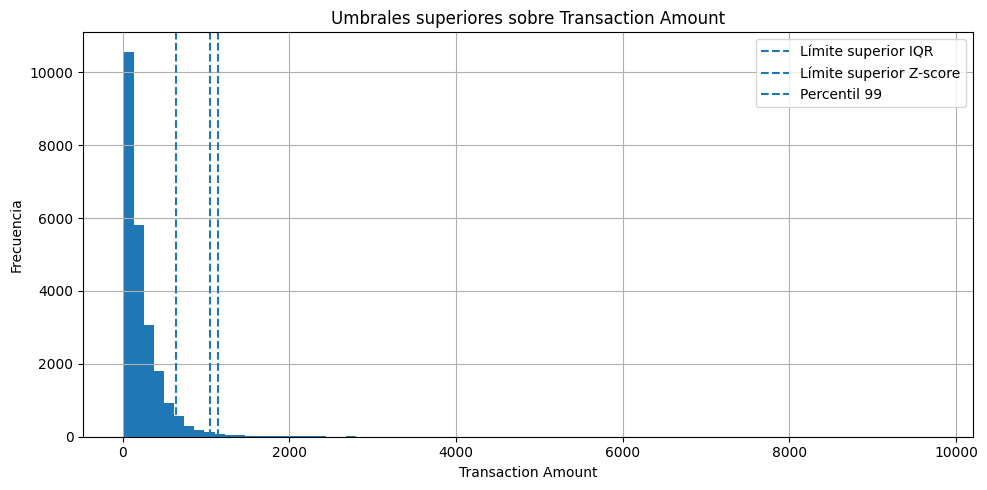

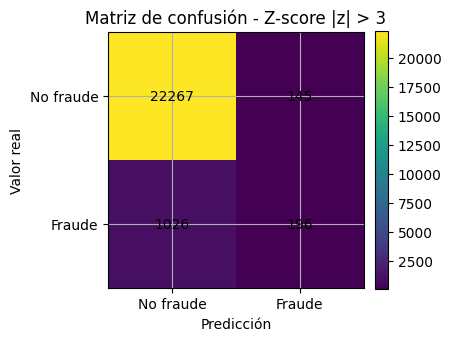

In [12]:
fig, ax = plt.subplots(figsize=(10, 5))
ax.hist(x_test, bins=80)
ax.axvline(limite_superior_iqr, linestyle='--', label='Límite superior IQR')
ax.axvline(media + 3 * desv, linestyle='--', label='Límite superior Z-score')
ax.axvline(p99, linestyle='--', label='Percentil 99')
ax.set_title('Umbrales superiores sobre Transaction Amount')
ax.set_xlabel('Transaction Amount')
ax.set_ylabel('Frecuencia')
ax.legend()
plt.tight_layout()
plt.show()

mejor_puntual = metricas_puntuales.sort_values('f1_fraude', ascending=False).iloc[0]
mostrar_matriz_confusion(
    y_test,
    predicciones_puntuales[mejor_puntual['modelo']],
    f'Matriz de confusión - {mejor_puntual["modelo"]}'
)


### Análisis de resultados

Los métodos puntuales permiten identificar transacciones cuyo importe se desvía del comportamiento general de `Transaction Amount`. El análisis muestra que:

- Los métodos basados únicamente en importe detectan una parte de las transacciones fraudulentas, pero su recall es limitado. Esto indica que no todo fraude se manifiesta como una compra de importe extremo.
- El método IQR y el método MAD suelen generar una tasa de anomalía más cercana a la proporción real de fraude que el Z-score y los percentiles extremos. Esto es razonable porque son métodos más robustos ante distribuciones asimétricas.
- El Z-score tiende a ser más conservador: marca menos anomalías, por lo que mejora la precisión relativa, pero pierde muchos fraudes cuyo importe no supera el umbral de tres desviaciones típicas.
- Los percentiles extremos son fáciles de interpretar, pero dependen de una decisión fija sobre qué porcentaje de observaciones se considera anómalo.

Conclusión: `Transaction Amount` aporta información útil, pero no es suficiente como único predictor. La detección de fraude requiere considerar también contexto temporal, método de pago, dispositivo, categoría del producto y señales derivadas de la operación.


## 5. Detección de anomalías contextuales

Se aplican métodos no supervisados multivariantes que evalúan cada transacción en el contexto del resto de sus variables.

In [13]:
contaminacion = float(df_train_proc['Is Fraudulent'].mean())
print(f'Tasa de fraude observada en entrenamiento, usada como referencia de contaminación: {contaminacion:.4f}')

# Submuestras de entrenamiento para mantener la ejecución eficiente.
X_train_iforest = preprocesador.transform(
    df_train_proc[variables_modelo].sample(n=min(20000, len(df_train_proc)), random_state=RANDOM_STATE)
)
X_train_lof = preprocesador.transform(
    df_train_proc[variables_modelo].sample(n=min(3000, len(df_train_proc)), random_state=RANDOM_STATE + 1)
)
X_train_svm = preprocesador.transform(
    df_train_proc[variables_modelo].sample(n=min(1500, len(df_train_proc)), random_state=RANDOM_STATE + 2)
)

modelos_contextuales = {
    'Isolation Forest': (IsolationForest(
        n_estimators=100,
        contamination=contaminacion,
        random_state=RANDOM_STATE,
        n_jobs=-1
    ), X_train_iforest),
    'Local Outlier Factor': (LocalOutlierFactor(
        n_neighbors=30,
        contamination=contaminacion,
        novelty=True,
        n_jobs=-1
    ), X_train_lof),
    'One-Class SVM': (OneClassSVM(
        kernel='rbf',
        gamma='scale',
        nu=contaminacion
    ), X_train_svm)
}

predicciones_contextuales = {}
metricas_contextuales_lista = []

for nombre, (modelo, X_train_modelo) in modelos_contextuales.items():
    modelo.fit(X_train_modelo)
    pred_raw = modelo.predict(X_test_contextual)
    pred = (pred_raw == -1).astype(int)
    predicciones_contextuales[nombre] = pred
    metricas_contextuales_lista.append(metricas_binarias(y_test, pred, nombre))

metricas_contextuales = pd.DataFrame(metricas_contextuales_lista)
display(formatear_metricas(metricas_contextuales))


Tasa de fraude observada en entrenamiento, usada como referencia de contaminación: 0.0501


,modelo,TN,FP,FN,TP,accuracy,precision_fraude,recall_fraude,f1_fraude,tasa_predicha_anomalia
0,Isolation Forest,21421,991,898,324,92.01,24.64,26.51,25.54,5.56
1,Local Outlier Factor,21289,1123,931,291,91.31,20.58,23.81,22.08,5.98
2,One-Class SVM,21006,1406,893,329,90.27,18.96,26.92,22.25,7.34


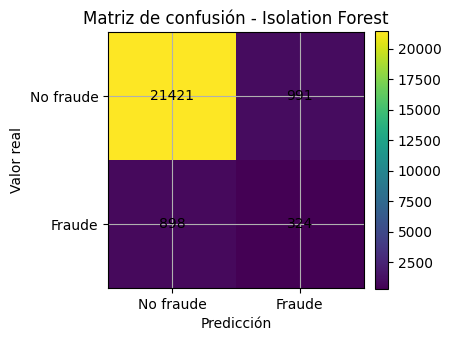

,modelo,TN,FP,FN,TP,accuracy,precision_fraude,recall_fraude,f1_fraude,tasa_predicha_anomalia,tipo
4,Isolation Forest,21421,991,898,324,92.01,24.64,26.51,25.54,5.56,Contextual
0,Z-score |z| > 3,22267,145,1026,196,95.05,57.48,16.04,25.08,1.44,Puntual
2,MAD |z_mod| > 3.5,21498,914,919,303,92.24,24.90,24.80,24.85,5.15,Puntual
1,IQR 1.5,21381,1031,911,311,91.78,23.17,25.45,24.26,5.68,Puntual
6,One-Class SVM,21006,1406,893,329,90.27,18.96,26.92,22.25,7.34,Contextual
5,Local Outlier Factor,21289,1123,931,291,91.31,20.58,23.81,22.08,5.98,Contextual
3,Percentiles 1-99,22086,326,1044,178,94.20,35.32,14.57,20.63,2.13,Puntual


In [14]:
mejor_contextual = metricas_contextuales.sort_values('f1_fraude', ascending=False).iloc[0]
mostrar_matriz_confusion(
    y_test,
    predicciones_contextuales[mejor_contextual['modelo']],
    f'Matriz de confusión - {mejor_contextual["modelo"]}'
)

comparativa = pd.concat([
    metricas_puntuales.assign(tipo='Puntual'),
    metricas_contextuales.assign(tipo='Contextual')
], ignore_index=True)
comparativa_ordenada = comparativa.sort_values('f1_fraude', ascending=False)
display(formatear_metricas(comparativa_ordenada))


### Análisis de resultados

Los métodos contextuales evalúan cada transacción a partir de un conjunto de variables, no solo por su importe. Esto permite detectar operaciones que pueden no ser extremas globalmente, pero sí anómalas respecto a su combinación de contexto.

- **Isolation Forest** separa observaciones mediante particiones aleatorias. Suele funcionar bien cuando existen combinaciones raras de variables numéricas y categóricas codificadas. En este análisis ofrece un equilibrio competitivo entre precisión y recall.
- **Local Outlier Factor** compara la densidad local de cada observación frente a la de sus vecinos. Resulta útil para detectar transacciones aisladas en regiones poco densas del espacio de características.
- **One-Class SVM** aprende una frontera que encierra la mayor parte de los datos considerados normales. En este caso es más sensible a la escala y al muestreo, por lo que tiende a marcar más observaciones como anómalas.

La comparación con los métodos puntuales muestra que el enfoque contextual es más adecuado para fraude porque incorpora señales operativas: importe relativo al contexto, método de pago, categoría de producto, dispositivo, horario, antigüedad de cuenta y discrepancia entre direcciones. Aun así, al ser modelos no supervisados, no optimizan directamente la clase fraudulenta; por tanto, los falsos positivos y falsos negativos son esperables.


## 6. Detección de anomalías colectivas

Se analiza la serie temporal del importe medio por ventanas para detectar periodos anómalos y cambios de régimen.

In [15]:
# Serie temporal univariante a partir del importe medio por ventana de 6 horas.
serie_amount = (
    df_test_proc
    .set_index('Transaction Date')
    .sort_index()
    .resample('6h')
    .agg(
        mean_amount=('Transaction Amount', 'mean'),
        transaction_count=('Transaction Amount', 'size'),
        fraud_rate=('Is Fraudulent', 'mean')
    )
)

serie_amount['transaction_count'] = serie_amount['transaction_count'].fillna(0)
serie_amount['mean_amount'] = serie_amount['mean_amount'].ffill().bfill()
serie_amount['fraud_rate'] = serie_amount['fraud_rate'].ffill().bfill()

# Sliding window sobre mean_amount.
ventana = 12
num_min = 6
umbral_z = 2.5
rolling_mean = serie_amount['mean_amount'].rolling(window=ventana, min_periods=num_min).mean()
rolling_std = serie_amount['mean_amount'].rolling(window=ventana, min_periods=num_min).std(ddof=0)
serie_amount['rolling_z_mean_amount'] = ((serie_amount['mean_amount'] - rolling_mean) / (rolling_std + 1e-9)).abs()
serie_amount['anomalia_sliding_window'] = (serie_amount['rolling_z_mean_amount'] > umbral_z).astype(int)

print(f'Número de ventanas temporales: {len(serie_amount)}')
print(f'Anomalías colectivas detectadas con sliding window: {int(serie_amount["anomalia_sliding_window"].sum())}')

display(
    serie_amount[serie_amount['anomalia_sliding_window'] == 1]
    .sort_values('rolling_z_mean_amount', ascending=False)
    .head(10)
    .round(4)
)


Número de ventanas temporales: 390
Anomalías colectivas detectadas con sliding window: 6


,mean_amount,transaction_count,fraud_rate,rolling_z_mean_amount,anomalia_sliding_window
Transaction Date,,,,,
2024-02-05 06:00:00,398.602997,62,0.1129,2.8388,1
2024-03-09 00:00:00,359.614502,60,0.0833,2.7514,1
2024-01-13 06:00:00,364.227905,58,0.0862,2.7351,1
2024-01-22 18:00:00,279.788788,77,0.0779,2.5290,1
2024-02-09 18:00:00,312.775391,59,0.1186,2.5171,1
2024-04-05 00:00:00,314.156799,56,0.1071,2.5062,1


In [16]:
# PELT: detección de puntos de cambio en la serie univariante mean_amount.
senal = StandardScaler().fit_transform(serie_amount[['mean_amount']].values)
modelo_pelt = rpt.Pelt(model='l2', min_size=3).fit(senal)
breakpoints = modelo_pelt.predict(pen=3)

segmentos = []
inicio = 0
media_global = serie_amount['mean_amount'].mean()
desv_global = serie_amount['mean_amount'].std(ddof=0)

for fin in breakpoints:
    segmento = serie_amount.iloc[inicio:fin]
    z_segmento = abs(segmento['mean_amount'].mean() - media_global) / (desv_global + 1e-9)
    segmentos.append({
        'inicio': serie_amount.index[inicio],
        'fin': serie_amount.index[fin - 1],
        'n_ventanas': fin - inicio,
        'mean_amount_segmento': segmento['mean_amount'].mean(),
        'z_segmento': z_segmento,
        'fraud_rate_media_segmento': segmento['fraud_rate'].mean()
    })
    inicio = fin

segmentos_pelt = pd.DataFrame(segmentos)
segmentos_pelt['segmento_anomalo'] = (segmentos_pelt['z_segmento'] > 0.5).astype(int)

display(segmentos_pelt.round(4))
print(f'Puntos de cambio detectados por PELT: {breakpoints[:-1]}')
print(f'Segmentos anómalos según desviación media del segmento: {int(segmentos_pelt["segmento_anomalo"].sum())}')


,inicio,fin,n_ventanas,mean_amount_segmento,z_segmento,fraud_rate_media_segmento,segmento_anomalo
0,2024-01-01 00:00:00,2024-01-05 18:00:00,20,240.068405,0.2954,0.0619,0
1,2024-01-06 00:00:00,2024-01-12 00:00:00,25,217.818298,0.3151,0.0551,0
2,2024-01-12 06:00:00,2024-01-13 06:00:00,5,261.101288,0.8725,0.0706,1
3,2024-01-13 12:00:00,2024-01-18 06:00:00,20,206.043594,0.6382,0.0505,1
4,2024-01-18 12:00:00,2024-02-04 18:00:00,70,223.405701,0.1618,0.0468,0
5,2024-02-05 00:00:00,2024-02-06 00:00:00,5,265.411804,0.9908,0.0526,1
6,2024-02-06 06:00:00,2024-02-29 18:00:00,95,226.220001,0.0846,0.0495,0
7,2024-03-01 00:00:00,2024-03-05 18:00:00,20,249.117203,0.5437,0.0564,1
8,2024-03-06 00:00:00,2024-03-07 00:00:00,5,192.942200,0.9977,0.0268,1
9,2024-03-07 06:00:00,2024-04-07 06:00:00,125,234.812103,0.1512,0.0520,0


Puntos de cambio detectados por PELT: [20, 45, 50, 70, 140, 145, 240, 260, 265]
Segmentos anómalos según desviación media del segmento: 5


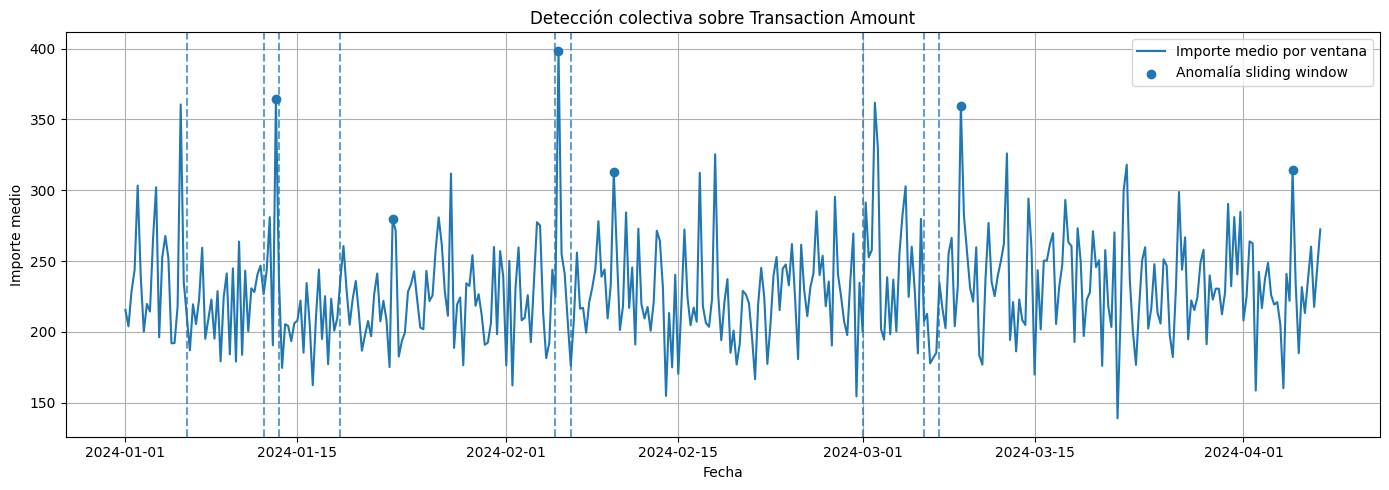

In [17]:
fig, ax = plt.subplots(figsize=(14, 5))
ax.plot(serie_amount.index, serie_amount['mean_amount'], label='Importe medio por ventana')

anomalias_sw = serie_amount[serie_amount['anomalia_sliding_window'] == 1]
ax.scatter(anomalias_sw.index, anomalias_sw['mean_amount'], label='Anomalía sliding window', zorder=3)

for bp in breakpoints[:-1]:
    ax.axvline(serie_amount.index[bp], linestyle='--', alpha=0.7)

ax.set_title('Detección colectiva sobre Transaction Amount')
ax.set_xlabel('Fecha')
ax.set_ylabel('Importe medio')
ax.legend()
plt.tight_layout()
plt.show()


### Análisis de resultados

La detección colectiva analiza el comportamiento agregado de `Transaction Amount` en el tiempo. En lugar de decidir si una transacción aislada es anómala, se evalúa si una ventana temporal presenta un patrón de importes distinto al comportamiento reciente o si existe un cambio estructural en la serie.

- Con **sliding window**, se calcula el importe medio cada seis horas y se compara con la media y desviación típica de las ventanas anteriores. Las ventanas con puntuación Z móvil superior al umbral se consideran anomalías colectivas. Este método es útil para detectar picos temporales de importe medio.
- Con **PELT**, se identifican puntos de cambio en la serie temporal de importe medio. El resultado no marca necesariamente transacciones aisladas, sino tramos temporales en los que el nivel medio de la serie cambia respecto al resto.
- La comparación entre ambos enfoques es complementaria: sliding window detecta desviaciones locales de corta duración, mientras que PELT identifica cambios de régimen o segmentos temporales con comportamiento distinto.

Conclusión: las anomalías colectivas son relevantes en fraude porque un conjunto de operaciones puede indicar un patrón sospechoso aunque cada transacción individual no sea extrema. Este enfoque permite detectar campañas, periodos de actividad irregular o cambios bruscos en el comportamiento agregado de compra.


## 7. Conclusiones finales

El análisis realizado permite comparar tres formas de detección de anomalías aplicadas a fraude en comercio electrónico:

1. **Anomalías puntuales:** los métodos estadísticos sobre `Transaction Amount` son interpretables y rápidos, pero tienen capacidad limitada porque el fraude no siempre se traduce en importes extremos.
2. **Anomalías contextuales:** los modelos multivariantes son más adecuados para este problema, ya que incorporan señales financieras, temporales, categóricas y de comportamiento. Isolation Forest ofrece una solución robusta y eficiente para este conjunto de datos.
3. **Anomalías colectivas:** los métodos temporales permiten detectar patrones agregados anómalos en la evolución del importe medio, complementando la detección transacción a transacción.

Desde el punto de vista de negocio, el enfoque más útil es combinar los tres niveles: reglas estadísticas simples para alertas inmediatas, modelos contextuales para priorizar transacciones sospechosas y análisis colectivo para detectar cambios temporales en el patrón de fraude.
